<a href="https://colab.research.google.com/github/camaleonica/VenomScope/blob/main/Notebook2_Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Parte 2: El modelo**
## Trabajo Práctico Obligatorio - Inteligencia Artificial

### Dónde estamos
En la parte 1 construimos el catálogo regional: secuencias de toxinas de 24 géneros del
noreste argentino, limpias, con su familia proteica anotada y separadas en dos grupos: las
que sirven para entrenar y las que reservamos para probar la detección de novedad.
En esta segunda parte, construiremos el modelo. Al terminar tenemos todo lo que la app necesita para funcionar,
guardado en disco.

### Qué haremos
1. **Embeddings**: convertir cada secuencia en una lista de números.
2. **Ver el espacio**: comprobar que los embeddings tienen estructura.
3. **Líneas de base**: medir contra qué nos estamos comparando.
4. **Clasificador**: predecir la familia proteica, y demostrar que el embedding aporta.
5. **Análisis de errores**: mirar en qué se equivoca y si los errores tienen sentido.
6. **Detector de novedad**: lo que hace valioso nuestro producto.
7. **Exportar**

# 0. Entorno y carga del catálogo


In [9]:
# scikit-learn y joblib en las MISMAS versiones que requirements.txt de la app.
# Si no, el clasificador se guarda con una versión y la app lo abre con otra, y
# algunos resultados cambian (con 1.6.1 el examen difícil de la sección 4.5 da
# otro número porque esa versión reparte los grupos de otra manera).
!pip -q install transformers scikit-learn==1.9.1 joblib==1.6.0

import os, json, time
import numpy as np
import pandas as pd
import torch
import sklearn, joblib

assert sklearn.__version__ == "1.9.1" and joblib.__version__ == "1.6.0", (
    f"Quedó scikit-learn {sklearn.__version__} / joblib {joblib.__version__}. "
    "Menú Entorno de ejecución -> Reiniciar sesión, y volver a ejecutar todo.")

print("torch        :", torch.__version__)
print("scikit-learn :", sklearn.__version__)
print("GPU          :", "sí -> " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no (vamos a usar CPU)")

torch : 2.11.0+cpu
GPU   : no (vamos a usar CPU)


In [10]:
from pathlib import Path

# El notebook se corre en Colab, pero también tiene que poder correrse en una
# compu cualquiera (por ejemplo para revisar algo sin esperar los 6 minutos de
# embeddings). Por eso busca el catálogo en los dos lados.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA = Path('/content/drive/MyDrive/TPO_IA')
    EN_COLAB = True
except ImportError:
    CARPETA = Path.cwd() / 'artifacts'          # el repo de la app
    EN_COLAB = False
    print('No estamos en Colab: se usa la carpeta local', CARPETA)

cat = pd.read_csv(CARPETA / 'catalogo_nea.csv')

# Chequeo de que venga del Notebook 1 y no de una versión vieja
ESPERADAS = {"sequence", "clase", "clase_modelable", "familia_valida", "grupo", "peptido_corto"}
faltan = ESPERADAS - set(cat.columns)
assert not faltan, f"Al catálogo le faltan columnas: {faltan}. ¿Es la salida del Notebook 1 actualizado?"

print(f"Catálogo: {len(cat)} secuencias")
print(f"  modelables (van al clasificador) : {cat['clase_modelable'].sum()}")
print(f"  reservadas (prueba de novedad)   : {(~cat['clase_modelable']).sum()}")
print(f"  clases distintas                 : {cat.loc[cat['clase_modelable'], 'clase'].nunique()}")
cat.head(3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Catálogo: 584 secuencias
  modelables (van al clasificador) : 518
  reservadas (prueba de novedad)   : 66
  clases distintas                 : 24


,accession,nombre_proteina,especie,genero_consultado,organism_id,familia_proteica,familia_nivel1,familia_valida,grupo,en_nea,largo,peptido_corto,sequence,clase,clase_modelable
0,I6L8L6,Basic phospholipase A2 homolog 2 (svPLA2 homol...,Bothrops brazili,Bothrops,157546,"Phospholipase A2 family, Group II subfamily, K...",Phospholipase A2 family,True,serpiente,False,121,False,SLFQLGKMILQETGKNPAASYGAYGCNCGVLGRGKPKDATDRCCYV...,Phospholipase A2 family,True
1,P04971,Thrombin-like enzyme batroxobin (BX) (SVTLE) (...,Bothrops atrox,Bothrops,8725,"Peptidase S1 family, Snake venom subfamily",Peptidase S1 family,True,serpiente,False,255,False,MVLIRVIANLLILQVSYAQKSSELVIGGDECDINEHPFLAFMYYSP...,Peptidase S1 family,True
2,P0C8M1,Basic phospholipase A2 BmTX-I (svPLA2) (EC 3.1...,Bothrops moojeni,Bothrops,98334,"Phospholipase A2 family, Group II subfamily, D...",Phospholipase A2 family,True,serpiente,False,121,False,DLWQFNKMIKKEVGKLPFPFYGAYGCYCGWGGRGEKPKDGTDRCCF...,Phospholipase A2 family,True


# 1. Embeddings
## El problema
Tenemos secuencias de texto como `MKTLLLTLVVVTIVCLDLGYT...` y queremos que la computadora
entienda cuáles se parecen entre sí. El problema es que parecerse no es compartir letras.

Dos péptidos pueden coincidir en apenas el 30% de los caracteres y aun así pertenecer a la
misma familia funcional, porque lo que importa es cómo se pliega la molécula y qué hace, no
la coincidencia literal. Y al revés: dos secuencias casi idénticas pueden comportarse
distinto si cambió un aminoácido clave.

Comparar carácter a carácter captura parte de eso, pero no todo. Y sobre todo, **no nos deja números con
los que hacer machine learning**.

### Nuestra idea:
Un **embedding** convierte cada secuencia en una lista de números (un vector) de manera que
las secuencias parecidas queden **cerca** y las distintas queden **lejos**.

Es como ubicar cada péptido en un mapa. Una vez que están todos ubicados:

- "parecerse" se vuelve "estar cerca", que se calcula con una resta;
- "esto no se parece a nada" se vuelve "está lejos de todos sus vecinos", que es justo
  nuestro detector de novedad;
- y podemos entrenar un clasificador encima.

Para ello, usaremos **ESM-2**, un modelo preentrenado con millones de secuencias de proteínas. Aprendió
qué combinaciones de aminoácidos son frecuentes y cuáles no, parecido a como un modelo de
lenguaje aprende qué palabras suelen ir juntas.

Nosotras no lo entrenamos, lo descargamos
ya entrenado y lo usamos para traducir nuestras secuencias a vectores.
Así, no entrenaremos uno propio ya que con 900 secuancias no alcanza ni de cerca.

Por otro lado, usaremos la versión pequeña (35M, 35 millones de parámetros) porque la app tiene que funcionar en un portátil, sin GPU y sin internet. La versión grande daría embeddings algo mejores, pero descargarla en el aula es un riesgo.

In [11]:
from transformers import AutoTokenizer, AutoModel

MODELO = "facebook/esm2_t12_35M_UR50D"   # ~150 MB, anda en CPU

tokenizer = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModel.from_pretrained(MODELO)
modelo.eval()      # modo evaluación: no vamos a entrenarlo, solo usarlo

device = "cuda" if torch.cuda.is_available() else "cpu"
modelo.to(device)

DIM = modelo.config.hidden_size
print(f"Modelo cargado: {MODELO}")
print(f"  dimensión del embedding: {DIM}")
print(f"  corriendo en: {device}")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo cargado: facebook/esm2_t12_35M_UR50D
  dimensión del embedding: 480
  corriendo en: cpu


## Cómo convertimos una secuencia en un solo vector

El modelo no devuelve un vector por secuencia: devuelve **un vector por cada aminoácido**.
Una secuencia de 120 aminoácidos sale como 120 vectores. Para tener un único vector por secuencia promediamos todos esos vectores.

In [12]:
IDS_ESPECIALES = torch.tensor(tokenizer.all_special_ids)

@torch.no_grad()                      # no calculamos gradientes: no estamos entrenando
def embeber(secuencias, batch=16):
    """Convierte una lista de secuencias en una matriz (n_secuencias x DIM)."""
    salida = []
    t0 = time.time()

    for i in range(0, len(secuencias), batch):
        lote = list(secuencias[i:i + batch])
        enc = tokenizer(lote, return_tensors="pt", padding=True, truncation=True, max_length=1024)
        enc = {k: v.to(device) for k, v in enc.items()}

        h = modelo(**enc).last_hidden_state          # (lote, largo, DIM)

        # Máscara: 1 en los aminoácidos de verdad, 0 en relleno y tokens especiales
        es_especial = torch.isin(enc["input_ids"], IDS_ESPECIALES.to(device))
        mascara = (~es_especial).float() * enc["attention_mask"].float()
        mascara = mascara.unsqueeze(-1)              # (lote, largo, 1)

        # Promedio sobre los aminoácidos reales
        vec = (h * mascara).sum(1) / mascara.sum(1).clamp(min=1)
        salida.append(vec.cpu().numpy())

        if (i // batch) % 10 == 0:
            print(f"  {min(i+batch, len(secuencias)):5d}/{len(secuencias)}", end="\r")

    print(f"\nListo en {time.time()-t0:.1f} s")
    return np.vstack(salida)

print("Función lista. Antes de usarla con todo el catálogo, la probamos.")

Función lista. Antes de usarla con todo el catálogo, la probamos.


### Prueba de la máscara

El embedding de una secuencia **no puede cambiar** según con quién le haya tocado
compartir lote. Si al procesarla junto a una secuencia larga el resultado cambia, es que el
relleno se está colando en el promedio.
Ese error no rompe nada pero contamina todos los
resultados: el modelo terminaría aprendiendo longitud en vez de biología. Por eso lo
chequeamos aquí y no después.

In [13]:
# Tomamos una secuencia corta y una larga
s_corta = cat["sequence"].iloc[cat["largo"].idxmin()]
s_larga = cat["sequence"].iloc[cat["largo"].idxmax()]
print(f"corta: {len(s_corta)} aa | larga: {len(s_larga)} aa")

# La corta, sola y acompañada por la larga (que la obliga a rellenarse)
sola = embeber([s_corta])[0]
en_lote = embeber([s_corta, s_larga])[0]

diferencia = np.abs(sola - en_lote).max()
print(f"\nDiferencia máxima entre ambas versiones: {diferencia:.2e}")

assert diferencia < 1e-3, (
    "El relleno está afectando el embedding. Revisar la máscara en la función embeber(): "
    "los tokens de relleno y los especiales no deben entrar en el promedio."
)
print("OK: el relleno no afecta el resultado. La máscara está bien.")

corta: 5 aa | larga: 553 aa
      1/1
Listo en 0.1 s
      2/2
Listo en 5.7 s

Diferencia máxima entre ambas versiones: 9.54e-07
OK: el relleno no afecta el resultado. La máscara está bien.


In [14]:
X = embeber(cat["sequence"].tolist())
print(f"Matriz de embeddings: {X.shape}   (una fila por secuencia, {DIM} números cada una)")


Listo en 415.4 s
Matriz de embeddings: (584, 480)   (una fila por secuencia, 480 números cada una)


In [15]:
# Guardamos los embeddings: calcularlos de nuevo tarda, y no cambian.
np.save("embeddings.npy", X)
print("Guardado: embeddings.npy")

# Chequeo de sanidad: ninguna fila debería ser todo ceros ni tener NaN
assert not np.isnan(X).any(), "Hay NaN en los embeddings"
assert (np.abs(X).sum(axis=1) > 0).all(), "Hay embeddings vacíos"
print("Chequeo OK: sin NaN y sin vectores vacíos")

Guardado: embeddings.npy
Chequeo OK: sin NaN y sin vectores vacíos


# 2. Espacio de embeddings

Antes de entrear nada, nos conviene mirar. Si los embeddings no tienen ninguna estructura, no
hay clasificador que lo arregle y es mejor enterarse ahora.

Los vectores tienen 480 dimensiones y no se pueden dibujar. Lo que hacemos es **aplastarlos
a 2** con PCA, que busca el plano donde los puntos quedan más desparramados. Se pierde
información, pero alcanza para ver si hay grupos.

Estas 2 dimensiones conservan el 46.9% de la variación original.


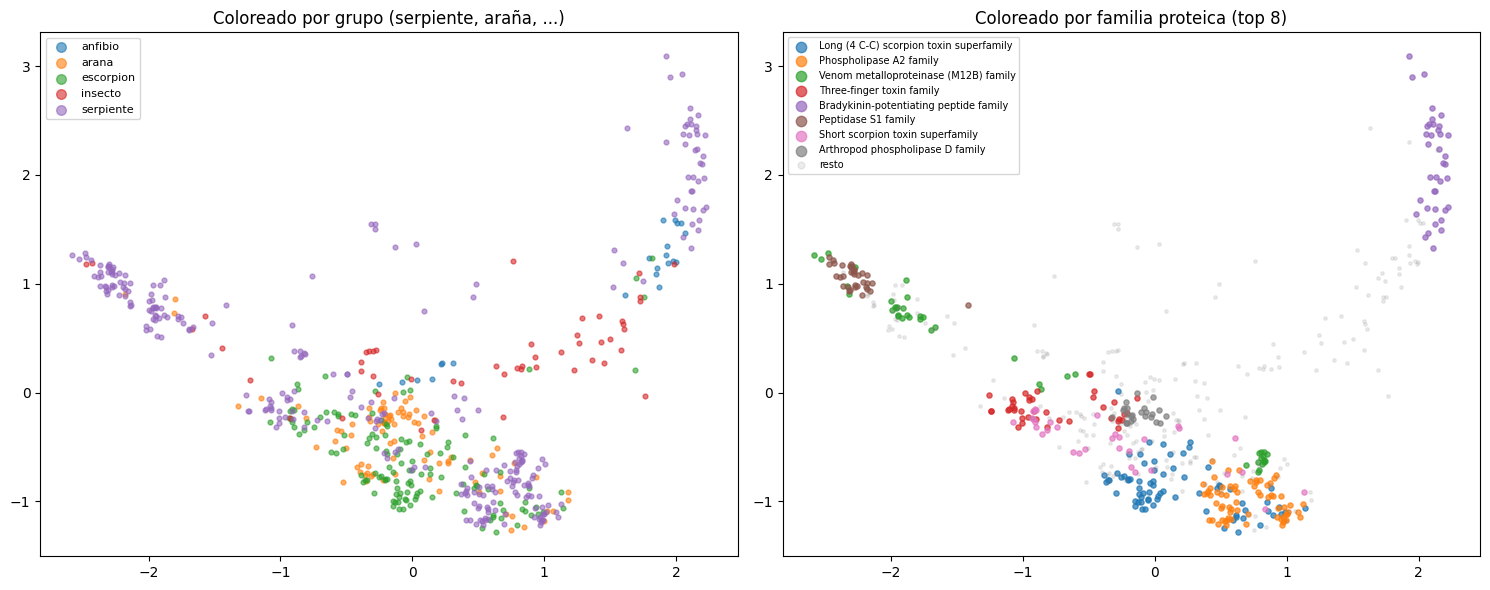

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
X2 = pca.fit_transform(X)

var = pca.explained_variance_ratio_
print(f"Estas 2 dimensiones conservan el {var.sum():.1%} de la variación original.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Izquierda: coloreado por grupo taxonómico
for grupo, sub in cat.groupby("grupo"):
    idx = sub.index
    ax1.scatter(X2[idx, 0], X2[idx, 1], s=12, alpha=0.6, label=grupo)
ax1.legend(markerscale=2, fontsize=8)
ax1.set_title("Coloreado por grupo (serpiente, araña, ...)")

# Derecha: coloreado por las familias más grandes
top = cat.loc[cat["clase_modelable"], "clase"].value_counts().head(8).index
for fam in top:
    idx = cat.index[cat["clase"] == fam]
    etiqueta = fam if len(fam) < 40 else fam[:37] + "..."
    ax2.scatter(X2[idx, 0], X2[idx, 1], s=14, alpha=0.7, label=etiqueta)
resto = cat.index[~cat["clase"].isin(top)]
ax2.scatter(X2[resto, 0], X2[resto, 1], s=6, alpha=0.15, color="gray", label="resto")
ax2.legend(markerscale=2, fontsize=7)
ax2.set_title("Coloreado por familia proteica (top 8)")

plt.tight_layout()
plt.show()

**Izquierda (por grupo):** los colores están mezclados. El violeta (serpientes): aparece en tres o cuatro zonas distintas del gráfico, separadas entre sí. Un mismo grupo taxonómico está desparramado por todo el mapa.

**Derecha (por familia):** cada color forma una mancha compacta. Peptidase S1 arriba a la izquierda, metaloproteinasas al lado, la superfamilia de escorpión abajo al centro, fosfolipasa A2 pegada, three-finger toxins en el medio, fosfolipasa D de artrópodo arriba a la derecha. Grupos nítidos y separados.

In [17]:
from sklearn.metrics import silhouette_score

# Autocontenida: calculamos la máscara acá mismo, no depende de celdas posteriores.
mask_mod = cat["clase_modelable"].values
sub   = cat.loc[mask_mod]
X_sub = X[mask_mod]

# OJO: sobre X completo (480 dimensiones), no sobre la proyección 2D.
# La afirmación es sobre el espacio real, no sobre el dibujo.
s_familia = silhouette_score(X_sub, sub["clase"], metric="cosine")
s_grupo   = silhouette_score(X_sub, sub["grupo"], metric="cosine")

print(f"Silhouette agrupando por FAMILIA : {s_familia:.3f}")
print(f"Silhouette agrupando por GRUPO   : {s_grupo:.3f}")
print()
print("El silhouette mide qué tan compactos y separados están los grupos.")
print("Va de -1 a 1: más alto = mejor agrupado.")
if s_familia > s_grupo:
    print(f"\nFamilia gana por {s_familia - s_grupo:.3f}. Queda MEDIDO que el espacio")
    print("se organiza por función y no por taxonomía")
else:
    print("\nLos grupos taxonómicos agrupan igual o mejor que las familias.")

Silhouette agrupando por FAMILIA : 0.304
Silhouette agrupando por GRUPO   : -0.080

El silhouette mide qué tan compactos y separados están los grupos.
Va de -1 a 1: más alto = mejor agrupado.

Familia gana por 0.384. Queda MEDIDO que el espacio
se organiza por función y no por taxonomía


# 3. Líneas de base

Dentro de un rato vamos a entrenar un clasificador y nos va a dar un número. El problema es
que un número solo no dice nada: **¿0.90 es bueno?** Depende de qué tan fácil era el
problema.

Por eso, antes de entrenar nada, medimos tres alternativas más tontas. Si el embedding no
le gana claramente a todas, no se justifica usarlo.

| Línea de base | Qué pregunta responde |
|---|---|
| Siempre la familia más común | ¿Se puede acertar sin mirar la secuencia? |
| Solo el largo de la secuencia | ¿Alcanza con saber si es corta o larga? |
| Composición de aminoácidos | ¿Alcanza con contar qué letras tiene, sin mirar el orden? |

La tercera es la que importa. Contar letras es lo más parecido a "entender la secuencia"
que se puede hacer sin IA: si ESM-2 no le gana, todo este trabajo sobra.

### Cómo medimos

**Validación cruzada:** no podemos tomarle examen al modelo con las mismas secuencias que
estudió, porque se las sabe de memoria. Partimos las 518 secuencias en 5 montones,
entrenamos con 4 y evaluamos con el que queda afuera, cinco veces rotando cuál queda
afuera. Así cada secuencia es evaluada una vez por un modelo que nunca la vio.

**Macro-F1 y no exactitud:** el macro-F1 promedia el desempeño de cada familia por
separado, así una familia de 5 ejemplos pesa igual que una de 73. Con exactitud a secas, un
modelo que ignore las familias chicas daría un número alto igual, y las familias chicas son
justo las interesantes para un laboratorio.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

AMINOACIDOS = sorted("ACDEFGHIKLMNPQRSTVWY")

# Las que tienen familia conocida y suficientes ejemplos: con estas se entrena.
# .to_numpy() y no .values: en pandas nuevo .values devuelve un tipo que sklearn no digiere.
mod = cat["clase_modelable"].to_numpy()
Xm  = X[mod]
ym  = cat.loc[mod, "clase"].to_numpy(dtype=object)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # estratificada: cada
                                                                  # montón conserva la
                                                                  # proporción de familias

def clasificador():
    """El mismo modelo para todas las comparaciones: lo único que cambia son los datos.

    StandardScaler pone todas las columnas en la misma escala antes de clasificar.
    class_weight='balanced' hace que las familias chicas pesen igual que las grandes.
    """
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=5000, class_weight="balanced"))

def macro_f1(modelo, datos):
    return f1_score(ym, cross_val_predict(modelo, datos, ym, cv=cv), average="macro")

# Los datos de cada línea de base
composicion = np.array([[s.count(a) / len(s) for a in AMINOACIDOS]
                        for s in cat.loc[mod, "sequence"]])          # 20 números por secuencia
solo_largo  = cat.loc[mod, ["largo"]].to_numpy(dtype=float)          # 1 número por secuencia

lineas = [
    ("siempre la familia más común", DummyClassifier(strategy="most_frequent"), Xm),
    ("solo el largo de la secuencia", clasificador(), solo_largo),
    ("composición de aminoácidos",    clasificador(), composicion),
    ("embeddings ESM-2",              clasificador(), Xm),
]

print("Macro-F1 (validación cruzada, 5 partes)\n")
resultados_base = {}
for nombre, clf, datos in lineas:          # 'clf' y no 'modelo': 'modelo' es ESM-2 y lo usamos en la sección 6
    resultados_base[nombre] = macro_f1(clf, datos)
    print(f"  {nombre:32s} {resultados_base[nombre]:.3f}")

ventaja = resultados_base["embeddings ESM-2"] - resultados_base["composición de aminoácidos"]
print(f"\nESM-2 le saca {ventaja:.3f} a contar aminoácidos.")
print("Esa diferencia es lo que aporta la IA: el resto se conseguía sin ella.")

Macro-F1 (validación cruzada, 5 partes)

  siempre la familia más común     0.010
  solo el largo de la secuencia    0.131
  composición de aminoácidos       0.808
  embeddings ESM-2                 0.931

ESM-2 le saca 0.124 a contar aminoácidos.
Esa diferencia es lo que aporta la IA: el resto se conseguía sin ella.


# 4. El clasificador

El número de arriba ya es el del clasificador que vamos a usar: regresión logística sobre
los embeddings. Acá miramos **cómo se reparte** ese número entre las familias, porque un
promedio puede esconder que a algunas les va pésimo.

### Por qué regresión logística y no algo más complejo

Con 518 ejemplos y 480 números por ejemplo, hay más columnas que filas. En esa situación
los modelos complejos se aprenden el ruido. Además, la regresión logística tiene dos cosas
que el producto necesita:

- **Devuelve probabilidades**, no una respuesta seca. Esa probabilidad es la "confianza"
  que la app le muestra al usuario, y es lo que permite avisar cuando el sistema no está
  seguro.
- **Es instantánea en CPU**, que es donde tiene que correr la demo.

El trabajo pesado ya lo hizo ESM-2 al construir el espacio. Encima de un buen espacio, un
modelo simple alcanza.

In [19]:
from sklearn.metrics import classification_report

# Predicciones de validación cruzada: cada secuencia predicha por un modelo que no la vio.
# Las guardamos porque la sección 5 las vuelve a usar para analizar los errores.
pred = cross_val_predict(clasificador(), Xm, ym, cv=cv)

reporte = pd.DataFrame(classification_report(ym, pred, output_dict=True, zero_division=0)).T
reporte = reporte.drop(index=[i for i in reporte.index
                             if i.startswith(("accuracy", "macro avg", "weighted avg"))])
reporte = reporte[["support", "precision", "recall", "f1-score"]].sort_values("support")
reporte["support"] = reporte["support"].astype(int)

print(f"Aciertos: {(pred == ym).mean():.1%}   |   Macro-F1: {f1_score(ym, pred, average='macro'):.3f}\n")
print("Las 24 familias, de la más chica a la más grande:")
display(reporte.round(3))

# ¿Les va peor a las familias chicas? Es la pregunta que condiciona el valor del producto:
# las familias poco representadas son las interesantes para un laboratorio.
correlacion = reporte["support"].corr(reporte["f1-score"], method="spearman")
print(f"\nCorrelación entre tamaño de la familia y desempeño: {correlacion:.2f}")
print("(cerca de 0 = el tamaño no importa; cerca de 1 = solo anda bien con las familias grandes)")

Aciertos: 96.9%   |   Macro-F1: 0.931

Las 24 familias, de la más chica a la más grande:


,support,precision,recall,f1-score
Long (3 C-C) scorpion toxin superfamily,5,0.500,0.600,0.545
Neurotoxin 30 (phrixotoxin) family,5,0.800,0.800,0.800
Flavin monoamine oxidase family,6,1.000,1.000,1.000
Frog skin active peptide (FSAP) family,7,1.000,1.000,1.000
Neurotoxin 09 (Tx3-6) family,7,0.875,1.000,0.933
Melittin family,7,1.000,0.714,0.833
Non-disulfide-bridged peptide (NDBP) superfamily,7,1.000,0.857,0.923
Neurotoxin 02 (plectoxin) family,8,0.750,0.750,0.750
Natriuretic peptide family,9,0.800,0.889,0.842
Long chain scorpion toxin family,10,0.909,1.000,0.952



Correlación entre tamaño de la familia y desempeño: 0.59
(cerca de 0 = el tamaño no importa; cerca de 1 = solo anda bien con las familias grandes)


## 4.5. El número de arriba está inflado, y lo podemos demostrar

Hay un problema con la forma en que medimos, y preferimos encontrarlo nosotras antes de
que lo encuentre otro.

El catálogo tiene **muchas secuencias casi idénticas**. Por ejemplo, fosfolipasas A2 de
distintas especies de *Bothrops* que se diferencian en unos pocos aminoácidos. Al partir
las 518 secuencias en 5 montones al azar, es muy probable que una variante quede entrenando
y su casi gemela quede en el examen.

Cuando eso pasa, el modelo la acierta, pero **no porque aprendió qué es una fosfolipasa**:
porque prácticamente ya la había visto. El 0.93 mide en parte memoria, no comprensión.

### Cómo lo medimos bien

1. Agrupamos las secuencias casi idénticas (distancia coseno menor a 0.02 entre ellas).
2. Repartimos los montones **por grupo entero**, nunca partiendo un grupo.

Así nos aseguramos de que, cuando una secuencia esté en el examen, ninguna casi gemela suya
estuvo entrenando. Es un examen mucho más difícil, y mucho más parecido a lo que le va a
pasar al producto en la vida real: un laboratorio trae un péptido que no se parece a lo que
ya está publicado.

Para que la comparación sea justa, medimos **las dos** de la misma manera: si solo
castigáramos a ESM-2 estaríamos haciendo trampa al revés.

In [20]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold

UMBRAL_GEMELAS = 0.02   # más chico = solo agrupa las realmente casi idénticas

grupos_gemelas = AgglomerativeClustering(
    n_clusters=None, distance_threshold=UMBRAL_GEMELAS,
    metric="cosine", linkage="average").fit_predict(Xm)

n_grupos = len(set(grupos_gemelas))
print(f"Las {len(Xm)} secuencias se reducen a {n_grupos} grupos de casi gemelas.")
print(f"O sea: en promedio cada grupo tiene {len(Xm) / n_grupos:.1f} variantes de lo mismo.\n")

# Control: ¿los grupos respetan las familias? Si un grupo mezclara familias distintas,
# el umbral sería demasiado grosero y estaríamos agrupando cosas que no van juntas.
por_grupo = pd.DataFrame({"clase": ym, "g": grupos_gemelas}).groupby("g")["clase"].nunique()
por_clase = pd.DataFrame({"clase": ym, "g": grupos_gemelas}).groupby("clase")["g"].nunique()
print(f"Grupos que mezclan más de una familia : {(por_grupo > 1).sum()} de {n_grupos}")
print(f"Familias con un solo grupo            : {(por_clase < 2).sum()} de {len(por_clase)}"
      "  <- estas son imposibles de evaluar así y arrastran el promedio para abajo\n")

cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def macro_f1_agrupado(datos):
    p = cross_val_predict(clasificador(), datos, ym, cv=cv_grupos, groups=grupos_gemelas)
    return f1_score(ym, p, average="macro")

print(f"{'':30s} {'al azar':>10s} {'agrupado':>10s}")
for nombre, datos in [("composición de aminoácidos", composicion), ("embeddings ESM-2", Xm)]:
    print(f"  {nombre:28s} {resultados_base[nombre]:>10.3f} {macro_f1_agrupado(datos):>10.3f}")

Las 518 secuencias se reducen a 111 grupos de casi gemelas.
O sea: en promedio cada grupo tiene 4.7 variantes de lo mismo.

Grupos que mezclan más de una familia : 5 de 111
Familias con un solo grupo            : 2 de 24  <- estas son imposibles de evaluar así y arrastran el promedio para abajo

                                  al azar   agrupado
  composición de aminoácidos        0.808      0.420
  embeddings ESM-2                  0.931      0.584


### Qué nos dice esto

El desempeño **cae bastante** cuando sacamos las casi gemelas: eso confirma que el primer
número estaba inflado. Era de esperar, y es la limitación más honesta que tenemos para
contar.

Pero hay algo más interesante: **la ventaja de ESM-2 sobre contar aminoácidos se agranda**
en el examen difícil. En el reparto al azar la diferencia era chica, porque las casi
gemelas son fáciles para cualquiera; cuando el examen obliga a generalizar de verdad, el
embedding es el que sigue sosteniéndose.

Dicho de otra forma: el reparto al azar nos hacía parecer mejores de lo que somos, y
además **escondía cuánto aporta la IA**.

Dos aclaraciones para no exagerar en la otra dirección:

- Dos familias quedan con un solo grupo de casi gemelas, así que es imposible tenerles
  examen: siempre fallan y tiran el promedio para abajo. El número real está algo por
  encima del que sale acá.
- Los grupos se arman con los mismos embeddings que estamos evaluando. No es circular para
  lo que nos importa (medir generalización), pero sí es una aproximación: lo riguroso sería
  agrupar por identidad de secuencia con una herramienta de bioinformática.

**Cuál reportamos.** Los dos, y en ese orden: el número al azar para comparar con lo que
suele publicarse, y el agrupado como el piso realista. Si en la defensa hay que elegir uno
solo, elegimos el agrupado.

# 5. Análisis de errores

Saber *cuánto* se equivoca no alcanza: hay que ver **en qué** se equivoca. Un modelo que
confunde cosas parecidas es muy distinto de uno que se equivoca al azar, aunque los dos
tengan el mismo número.

Tres preguntas concretas:

1. **¿Las confusiones tienen sentido biológico?** Si confunde dos superfamilias
   emparentadas, está captando algo real. Si confunde cosas que no tienen nada que ver,
   está adivinando.
2. **¿Le va peor con los péptidos cortos?** La app les pone una advertencia; queremos saber
   si esa advertencia está justificada o la pusimos por las dudas.
3. **¿Se cumple lo que anticipamos en el Notebook 1?** Ahí dijimos que serpientes y
   anfibios producen péptidos de la misma familia, y que un clasificador los iba a mezclar.
   Si eso aparece acá, el análisis del Notebook 1 queda confirmado.

In [21]:
sub_mod = cat.loc[mod].reset_index(drop=True)      # el catálogo, solo las modelables
err = pred != ym                                   # dónde se equivocó la validación cruzada

print(f"Se equivoca en {err.sum()} de {len(ym)} secuencias ({err.mean():.1%})\n")

# --- Pregunta 2: ¿los péptidos cortos son más difíciles? ---
cortos = sub_mod["peptido_corto"].to_numpy()
print("Error según el largo de la secuencia:")
print(f"  péptidos cortos (<20 aa) : {err[cortos].mean():>6.1%}   ({cortos.sum()} secuencias)")
print(f"  el resto                 : {err[~cortos].mean():>6.1%}   ({(~cortos).sum()} secuencias)")

# --- Pregunta 1 y 3: qué confunde con qué ---
print("\nConfusiones más frecuentes (real -> predicha):")
confusiones = (pd.DataFrame({"real": ym[err], "predicha": pred[err],
                             "grupo": sub_mod.loc[err, "grupo"].to_numpy(dtype=object)})
               .value_counts().reset_index(name="veces"))
for _, f in confusiones.head(8).iterrows():
    print(f"  {f['veces']}x  {f['real'][:36]:36s} -> {f['predicha'][:36]:36s} [{f['grupo']}]")

Se equivoca en 16 de 518 secuencias (3.1%)

Error según el largo de la secuencia:
  péptidos cortos (<20 aa) :   1.3%   (75 secuencias)
  el resto                 :   3.4%   (443 secuencias)

Confusiones más frecuentes (real -> predicha):
  3x  Long (4 C-C) scorpion toxin superfam -> Long (3 C-C) scorpion toxin superfam [escorpion]
  2x  Melittin family                      -> MCD family                           [insecto]
  1x  Long (3 C-C) scorpion toxin superfam -> Long (4 C-C) scorpion toxin superfam [escorpion]
  1x  Long (4 C-C) scorpion toxin superfam -> Natriuretic peptide family           [escorpion]
  1x  Long (3 C-C) scorpion toxin superfam -> Neurotoxin 02 (plectoxin) family     [escorpion]
  1x  Long (4 C-C) scorpion toxin superfam -> Neurotoxin 02 (plectoxin) family     [escorpion]
  1x  Natriuretic peptide family           -> Long chain scorpion toxin family     [serpiente]
  1x  Neurotoxin 02 (plectoxin) family     -> Long (4 C-C) scorpion toxin superfam [arana]


In [22]:
# ¿Hay familias que aparecen en varios grupos animales?
# Es lo que anticipamos en el Notebook 1: serpientes y anfibios produciendo péptidos de la
# misma familia. Si el clasificador las acierta igual, es porque aprendió función y no
# taxonomía, que es justo lo que queremos.
cruzadas = (sub_mod.groupby("clase")["grupo"]
            .agg(n_grupos="nunique", grupos=lambda g: ", ".join(sorted(set(g)))))
cruzadas = cruzadas[cruzadas["n_grupos"] > 1].sort_values("n_grupos", ascending=False)
cruzadas["secuencias"] = reporte["support"]
cruzadas["f1"] = reporte["f1-score"].round(3)

print(f"{len(cruzadas)} de las {sub_mod['clase'].nunique()} familias aparecen en más de un grupo animal:\n")
display(cruzadas[["secuencias", "grupos", "f1"]])

otras = reporte.loc[~reporte.index.isin(cruzadas.index), "f1-score"]
print(f"Desempeño promedio en las familias que cruzan grupos : {cruzadas['f1'].mean():.3f}")
print(f"Desempeño promedio en las demás                      : {otras.mean():.3f}")

5 de las 24 familias aparecen en más de un grupo animal:



,secuencias,grupos,f1
clase,,,
Bradykinin-potentiating peptide family,38,"anfibio, serpiente",1.000
Bradykinin-related peptide family,15,"anfibio, insecto",1.000
Natriuretic peptide family,9,"escorpion, serpiente",0.842
Peptidase S1 family,35,"insecto, serpiente",1.000
Venom metalloproteinase (M12B) family,43,"escorpion, serpiente",1.000


Desempeño promedio en las familias que cruzan grupos : 0.968
Desempeño promedio en las demás                      : 0.921


### Las respuestas a las tres preguntas

**1. Las confusiones tienen sentido biológico.** Casi todas pasan entre familias
emparentadas: las dos superfamilias de toxinas de escorpión se confunden entre sí, y
melitina con MCD, que son las dos de insecto y actúan sobre membranas. El modelo no está
adivinando: está mezclando cosas que de verdad se parecen. Un error así es mucho menos
grave que confundir una toxina de serpiente con una de araña.

**2. Con los péptidos cortos le va MEJOR, no peor.** Esto nos sorprendió: esperábamos lo
contrario y la app tiene una advertencia basada en esa expectativa.

Pero el número no dice lo que parece. Casi todos los péptidos cortos del catálogo son
potenciadores de bradiquinina, una familia grande, muy distintiva y muy bien representada.
El modelo no acierta *porque sean cortos*: acierta porque **esos** cortos en particular son
fáciles. Con un péptido corto de una familia desconocida no tenemos ninguna evidencia de
que ande bien, y seguimos teniendo el argumento de fondo: con 9 aminoácidos hay mucha menos
información que con 120.

**Qué hacemos con la advertencia de la app: la dejamos, pero cambiamos lo que dice.** En
vez de afirmar que el resultado es menos confiable, conviene decir que no lo pudimos
verificar. Es la diferencia entre inventar una limitación y reconocer que no sabemos.

**3. Se confirma lo que anticipamos en el Notebook 1.** Hay familias que aparecen en
grupos animales sin ningún parentesco: los potenciadores de bradiquinina en serpientes y
anfibios, las peptidasas en insectos y serpientes. Y el clasificador **las acierta mejor
que al resto**, no peor.

Eso cierra el argumento central del trabajo: el espacio de embeddings se organiza por
**lo que la molécula hace**, no por el animal del que salió. Primero lo dijimos en el
Notebook 1, después lo medimos con el silhouette en la sección 2, y ahora se confirma en el
comportamiento del clasificador.

> **Una limitación que sí queda en pie:** la correlación entre el tamaño de la familia y el
> desempeño es moderada, así que a las familias chicas les va algo peor. Es el sesgo de la
> base de datos del que habla el Notebook 1, y afecta justamente a las familias menos
> estudiadas, que son las interesantes.

# 6. Detector de novedad

Esta es la pieza más valiosa del producto, y conviene entender por qué.

**El clasificador tiene un defecto que no se puede arreglar:** conoce 24 familias y está
obligado a elegir una. No tiene la opción de contestar "esto no lo conozco". Si le damos
una toxina de una familia que nunca vio, va a elegir igual, y puede hacerlo con mucha
confianza. Si el producto fuera solo el clasificador, el investigador se lo creería.

El detector de novedad es lo que lo salva: responde la otra pregunta, **"¿cuánto hay que
confiar en esa respuesta?"**.

### Cómo funciona, en cuatro pasos

1. Medimos la distancia de la secuencia nueva a la **más parecida de todo el catálogo**.
2. Ese número solo no significa nada. ¿0.43 es mucho o poco?
3. Armamos una vara de medir: tomamos cada toxina conocida y le medimos la distancia a su
   pariente más cercano. Eso responde *entre toxinas que ya conocemos, ¿qué tan lejos suele
   estar una de su pariente más próximo?*
4. El puntaje es dónde cae la secuencia nueva en esa vara. **97 significa: está más lejos
   de lo conocido que el 97% de las toxinas del catálogo respecto de su pariente más
   cercano.**

### Cómo lo evaluamos

Acá es donde se paga la decisión del Notebook 1 de **no tirar las clases chicas**. Las 66
secuencias reservadas (familias con menos de 5 ejemplos, o sin familia asignada) nunca
entraron al entrenamiento. Son exactamente el caso que el detector tiene que saber marcar,
y nos dan un examen real en vez de uno simulado.

In [23]:
from sklearn.metrics import roc_auc_score

def a_unitarios(A):
    """Normaliza cada fila para poder comparar direcciones y no tamaños."""
    return A / np.clip(np.linalg.norm(A, axis=1, keepdims=True), 1e-12, None)

def distancias(Q, R):
    """Distancia coseno: 0 = idénticas, cuanto más grande más distintas."""
    return np.clip(1.0 - a_unitarios(Q) @ a_unitarios(R).T, 0.0, None)

# --- Paso 3: la vara de medir ---
# Distancia de cada toxina conocida a su vecina más cercana, sin contarse a sí misma.
D = distancias(Xm, Xm)
np.fill_diagonal(D, np.inf)
escala = np.sort(D.min(axis=1))

def puntaje_novedad(d):
    """Dónde cae una distancia dentro de la vara, de 0 a 100."""
    return 100.0 * np.searchsorted(escala, d, side="left") / len(escala)

print("La vara de medir (distancia al pariente más cercano, entre toxinas conocidas):")
for p in (50, 75, 90, 95, 99):
    print(f"  el {p}% de las conocidas está a menos de {np.percentile(escala, p):.3f}")

# --- El examen: las 66 reservadas ---
d_reservadas = distancias(X[~mod], Xm).min(axis=1)
p_reservadas = np.array([puntaje_novedad(d) for d in d_reservadas])

auc = roc_auc_score(np.r_[np.zeros(len(escala)), np.ones(len(d_reservadas))],
                    np.r_[escala, d_reservadas])
print(f"\nAUC = {auc:.3f}   (0.5 sería tirar una moneda, 1.0 sería perfecto)")

La vara de medir (distancia al pariente más cercano, entre toxinas conocidas):
  el 50% de las conocidas está a menos de 0.005
  el 75% de las conocidas está a menos de 0.009
  el 90% de las conocidas está a menos de 0.014
  el 95% de las conocidas está a menos de 0.019
  el 99% de las conocidas está a menos de 0.042

AUC = 0.958   (0.5 sería tirar una moneda, 1.0 sería perfecto)


In [24]:
# ¿Dónde ponemos el corte? No hay una respuesta técnica: es una decisión de negocio.
# Por cómo está construida la vara, un umbral de 95 implica que el 5% de las toxinas
# CONOCIDAS también lo supera. Esas son falsas alarmas, por diseño.
print(f"{'umbral':>8s} {'detecta de las 66':>20s} {'falsas alarmas':>16s}")
for u in (50, 75, 90, 95, 99):
    print(f"{u:>8d} {(p_reservadas >= u).mean():>19.0%} {100 - u:>15d}%")

print("\nLas reservadas que el detector MÁS se pierde (las que parecen conocidas):")
res = cat.loc[~mod].reset_index(drop=True)
for i in np.argsort(p_reservadas)[:5]:
    print(f"  novedad {p_reservadas[i]:>3.0f}  {res.loc[i, 'nombre_proteina'][:46]:46s} "
          f"[{res.loc[i, 'familia_nivel1'][:30]}]")

  umbral    detecta de las 66   falsas alarmas
      50                100%              50%
      75                 98%              25%
      90                 89%              10%
      95                 71%               5%
      99                 29%               1%

Las reservadas que el detector MÁS se pierde (las que parecen conocidas):
  novedad  74  U5-ctenitoxin-Pk1a (U5-CNTX-Pk1a) (Neurotoxin  [Neurotoxin 04 (omega-agtx) fam]
  novedad  77  Putative sodium channel toxin Ts30 (Putative N [Sin familia asignada]
  novedad  83  Beta/kappa-theraphotoxin-Gi1a (Beta/kappa-TRTX [Phrixotoxin family]
  novedad  84  U1-sicaritoxin-Li1b (U1-SCRTX-Li1b) (LiTx2)    [Neurotoxin 28 (Litx) family]
  novedad  88  U2-sicaritoxin-Li1b (U2-SCRTX-Li1b)            [Neurotoxin 39 family]


### Dónde ponemos el corte: una decisión de negocio, no técnica

La tabla de arriba no tiene una fila "correcta". Bajar el umbral detecta más novedades pero
genera más falsas alarmas; subirlo hace lo contrario. Lo que decide es **cuánto cuesta cada
error**, y en este producto no cuestan lo mismo:

- **Falsa alarma:** un investigador mira una secuencia y en diez minutos la descarta.
- **Novedad perdida:** el candidato que no se parecía a nada queda enterrado en una
  planilla. Es exactamente el problema que el Notebook 1 dijo que veníamos a resolver.

Con esa asimetría, conviene equivocarse para el lado de la falsa alarma.

**Los valores que usa la app hoy son 75 y 95**, pero la tabla muestra que 90 puede ser un
mejor punto: detecta bastante más a cambio de pocas falsas alarmas extra. **Queda para
decidir entre las cuatro**, y se cambia en una línea de `config.json` sin tocar nada más.

### Lo que el detector se pierde

Las reservadas con puntaje bajo no son errores caprichosos: suelen ser toxinas de una
especie emparentada con otra que **sí** está en el entrenamiento. El detector dice "esto se
parece a algo que conozco" y tiene razón; lo que pasa es que la familia está anotada
aparte. Es una limitación honesta: el detector mide parecido, no novedad científica.

### La prueba de fuego: tres toxinas de afuera

Las 66 reservadas son del mismo catálogo, así que el examen todavía es "de casa". La prueba
de verdad es darle toxinas de animales que **no existen en nuestra región**, de familias que
el modelo jamás vio.

Elegimos tres que además tienen una historia comercial, porque es el argumento del producto:
las tres se convirtieron en medicamentos reales.

| Toxina | Animal | En qué se convirtió |
|---|---|---|
| Ziconotida | caracol marino (*Conus*) | Prialt, analgésico |
| Exendina-4 | monstruo de Gila (lagarto) | Exenatida, diabetes tipo 2 |
| ShK | anémona de mar | Dalazatida, enfermedades autoinmunes |

Si VenomScope hubiera estado disponible cuando aparecieron, ¿las habría marcado?

In [25]:
EXTERNAS = {
    "Ziconotida (caracol marino)":    "CKGKGAKCSRLMYDCCTGSCRSGKC",
    "Exendina-4 (monstruo de Gila)":  "HGEGTFTSDLSKQMEEEAVRLFIEWLKNGGPSSGAPPPS",
    "ShK (anémona de mar)":           "RSCIDTIPKSRCTAFQCKHSMKYRLSFCRKTCGTC",
}

# Entrenamos con TODAS las modelables (ya no estamos evaluando, acá queremos el modelo final)
modelo_final = clasificador().fit(Xm, ym)

X_ext = embeber(list(EXTERNAS.values()))
probas = modelo_final.predict_proba(X_ext)
d_ext = distancias(X_ext, Xm).min(axis=1)

for nombre, p, d in zip(EXTERNAS, probas, d_ext):
    familia = modelo_final.classes_[p.argmax()]
    print(f"\n{nombre}")
    print(f"   el clasificador dice : {familia[:45]} ({p.max():.0%} de confianza)")
    print(f"   la novedad dice      : {puntaje_novedad(d):.0f}/100")

      3/3
Listo en 0.3 s

Ziconotida (caracol marino)
   el clasificador dice : Short scorpion toxin superfamily (96% de confianza)
   la novedad dice      : 98/100

Exendina-4 (monstruo de Gila)
   el clasificador dice : Non-disulfide-bridged peptide (NDBP) superfam (72% de confianza)
   la novedad dice      : 98/100

ShK (anémona de mar)
   el clasificador dice : Short scorpion toxin superfamily (96% de confianza)
   la novedad dice      : 99/100


### Lo que acabamos de ver

**El clasificador se equivoca, y se equivoca con muchísima confianza.** Dice "toxina de
escorpión" para una molécula de caracol marino, con un porcentaje altísimo. Está mal, y no
tiene forma de no estar mal: solo conoce 24 familias y tiene que elegir una.

**El detector de novedad acierta en las tres.** Las marca lejísimos de todo lo conocido.

Eso es exactamente lo que hace la app: nunca muestra la familia sola. La muestra junto al
puntaje de novedad, y cuando la novedad es alta avisa que la familia sugerida es solo la
menos lejana y hay que tomarla con cuidado.

> **La respuesta a "¿qué pasa cuando la IA se equivoca?"**: el sistema se equivoca en la
> familia, pero acierta en lo que importa, que es avisar que no sabe. Por separado ninguna
> de las dos piezas serviría; juntas, sí.

Y respondiendo la pregunta de arriba: sí, VenomScope habría marcado las tres como
prioritarias. Son tres medicamentos que existen hoy.

# 7. Exportar

Acá termina el notebook y empieza la app. Guardamos cinco archivos, que son el
**contrato** entre las dos partes:

| Archivo | Qué es |
|---|---|
| `catalogo_nea.csv` | El catálogo (viene del Notebook 1, no lo tocamos) |
| `embeddings.npy` | Los 480 números de cada secuencia, en el mismo orden que el CSV |
| `clasificador.joblib` | El clasificador ya entrenado |
| `proyeccion3d.joblib` | El mapa 3D ya calculado, para que la app lo dibuje siempre igual |
| `config.json` | Umbrales, la vara de medir la novedad y las métricas |

La lista no es decorativa: la app revisa que estén los cinco y que `config.json`
tenga todas las claves que necesita. Si falta algo, avisa qué falta en vez de
reventar a la mitad de la demo. La lista vive en `venomscope/contrato.py`.

**La regla crítica:** la app tiene que calcular los embeddings **exactamente igual**
que este notebook. Mismo modelo, mismo promedio con máscara, misma normalización.
Si difieren, el clasificador recibe números distintos a los que vio al entrenarse y
se equivoca sin dar ningún error, que es la peor clase de falla: silenciosa.

Por eso `config.json` guarda el nombre del modelo: la app lo compara al arrancar y
se niega a funcionar si no coincide.

In [26]:
import joblib
from datetime import date
from sklearn.decomposition import PCA

SALIDA = CARPETA / "artifacts"
SALIDA.mkdir(parents=True, exist_ok=True)

UMBRAL_CONFIANZA = 0.5                       # por debajo, la app avisa "confianza baja"
UMBRALES_NOVEDAD = {"medio": 75, "alto": 90} # el corte alto lo decidió el grupo (sección 6)

# --- El mapa 3D de la app ---
# Se calcula acá una sola vez y se guarda entero. Si la app lo recalculara en
# cada apertura, el dibujo podría salir espejado: el signo de cada eje de PCA es
# arbitrario. Guardándolo, el mapa es siempre idéntico.
pca3d = PCA(n_components=3, random_state=0).fit(X)
joblib.dump({"pca": pca3d, "coords": pca3d.transform(X)}, SALIDA / "proyeccion3d.joblib")
varianza_mapa = float(pca3d.explained_variance_ratio_.sum())

# --- Qué pasa con cada posición del control de sensibilidad de la app ---
# Las falsas alarmas son 100 - umbral, por cómo está construida la escala.
curva = {str(u): round(float((p_reservadas >= u).mean()), 4) for u in range(80, 100)}

metricas = {
    "macro_f1_mayoritaria": resultados_base["siempre la familia más común"],
    "macro_f1_composicion": resultados_base["composición de aminoácidos"],
    "macro_f1_esm2":        resultados_base["embeddings ESM-2"],
    # Los dos números de la sección 4.5: el examen difícil, que es el realista
    "macro_f1_composicion_agrupado": macro_f1_agrupado(composicion),
    "macro_f1_esm2_agrupado":        macro_f1_agrupado(Xm),
    "novedad_auc": auc,
    "reservadas_nivel_alto":         float((p_reservadas >= UMBRALES_NOVEDAD["alto"]).mean()),
    "reservadas_nivel_medio_o_alto": float((p_reservadas >= UMBRALES_NOVEDAD["medio"]).mean()),
}

config = {
    "version": "1.0",
    "generado_por": "Notebook2_Modelo.ipynb",
    "fecha": date.today().isoformat(),
    "modelo_esm": MODELO,
    "dim": DIM,
    "n_catalogo": len(cat),
    "n_reservadas": int((~mod).sum()),
    "clasificador": {"umbral_confianza": UMBRAL_CONFIANZA},
    "novedad": {
        "k_vecinos": 5,
        "umbrales_puntaje": UMBRALES_NOVEDAD,
        "escala": escala.round(6).tolist(),   # la vara de medir, que la app necesita entera
        "curva_umbrales": curva,
    },
    "mapa3d": {"varianza_conservada": round(varianza_mapa, 4)},
    "metricas": {k: round(float(v), 4) for k, v in metricas.items()},
}

np.save(SALIDA / "embeddings.npy", X)
joblib.dump(modelo_final, SALIDA / "clasificador.joblib")
cat.to_csv(SALIDA / "catalogo_nea.csv", index=False)
(SALIDA / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))

ESPERADOS = ["catalogo_nea.csv", "embeddings.npy", "clasificador.joblib",
             "proyeccion3d.joblib", "config.json"]
print(f"Guardado en {SALIDA}:")
for nombre in ESPERADOS:
    archivo = SALIDA / nombre
    assert archivo.exists(), f"No se generó {nombre}: la app no va a arrancar sin eso."
    print(f"  {nombre:22s} {archivo.stat().st_size / 1024:8.1f} KB")

print("\nLo que medimos:")
for k, v in config["metricas"].items():
    print(f"  {k:32s} {v}")

Guardado en /content/drive/MyDrive/TPO_IA/artifacts:
  catalogo_nea.csv          219.7 KB
  embeddings.npy           1095.1 KB
  clasificador.joblib       103.7 KB
  proyeccion3d.joblib        15.3 KB
  config.json                15.4 KB

Lo que medimos:
  macro_f1_mayoritaria             0.0103
  macro_f1_composicion             0.8077
  macro_f1_esm2                    0.9312
  macro_f1_composicion_agrupado    0.4197
  macro_f1_esm2_agrupado           0.5841
  novedad_auc                      0.9585
  reservadas_nivel_alto            0.8939
  reservadas_nivel_medio_o_alto    0.9848
